# Customer Churn Analysis
End-to-end analysis on a subscription business: Excel -> SQLite -> cleaning -> merge -> KPIs -> visuals -> insights.

**Dataset:** sample of 21 customers across 3 tables (`db_customer`, `db_subscription`, `db_support`). Results are directional, not statistically significant.

In [1]:
import pandas as pd
import numpy as np
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

In [2]:
FILE = "customer_churn_data_raw.xlsx"

customer = pd.read_excel(FILE, sheet_name="db_customer")
subs = pd.read_excel(FILE, sheet_name="db_subscription")
support = pd.read_excel(FILE, sheet_name="db_support")
for name, df in [("customer", customer), ("subs", subs), ("support", support)]:
 print(name, df.shape)




customer (21, 8)
subs (21, 11)
support (9, 6)


In [3]:
print("customer",customer.shape)
print("subs",subs.shape)
print("support",support.shape)

customer (21, 8)
subs (21, 11)
support (9, 6)


In [4]:
conn = sqlite3.connect('customer_churn.db')
customer.to_sql("customers", conn, if_exists="replace", index=False)

subs.to_sql("subscriptions", conn, if_exists="replace", index=False)

support.to_sql("support", conn, if_exists="replace", index=False)

9

In [5]:
query = "SELECT * FROM customers LIMIT 5"

pd.read_sql_query(query, conn)

,customerid,name,country,state,gender,dob,interests,pincode
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12 00:00:00,travel,None
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23 00:00:00,NaN,None
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15 00:00:00,movie,None
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30 00:00:00,NaN,None
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05 00:00:00,drama,None


In [6]:
cursor = conn.cursor()

cursor.execute("SELECT name FROM sqlite_master WHERE type='table'")

print(cursor.fetchall())

[('customers',), ('subscriptions',), ('support',)]


In [7]:
customer.tail(5)

,customerid,name,country,state,gender,dob,interests,pincode
16,0020-JDNXP,rikim,India,Meghalaya,Female,1994-08-19,NaN,NaN
17,0021-IKXGC,vishakha,India,Rajasthan,Female,2000-09-02,NaN,NaN
18,0022-TCJCI,raghvendra,India,Telangana,Male,1983-12-30,NaN,NaN
19,0023-HGHWL,rishabh,India,Uttar Pradesh,Men,1991-05-14,NaN,NaN
20,0023-UYUPN,sudevi,India,Maharashtra,Women,1977-10-06,NaN,NaN


In [8]:
customer.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   customerid  21 non-null     str           
 1   name        21 non-null     str           
 2   country     18 non-null     str           
 3   state       21 non-null     str           
 4   gender      21 non-null     str           
 5   dob         21 non-null     datetime64[us]
 6   interests   4 non-null      str           
 7   pincode     0 non-null      float64       
dtypes: datetime64[us](1), float64(1), str(6)
memory usage: 1.4 KB


In [9]:
# a. rename col - name to customer_name
# b. drop columns - interest and pincode
# c. change data type - dob
# d. data standardization - gender
# e. fix missing values (using existing data) - country

# a. rename col - name to customer_name
customer.rename(columns = {'name' : 'customer_name'}, inplace= True)


In [10]:
customer.columns.tolist()

['customerid',
 'customer_name',
 'country',
 'state',
 'gender',
 'dob',
 'interests',
 'pincode']

In [11]:

# b. drop columns - interest and pincode

# df_db_customer.drop(df_db_customer.columns[-2:], axis=1)
# df_db_customer.drop(df_db_customer.columns[6:], axis=1)

customer.drop(columns=['interests', 'pincode'], inplace=True, errors = 'ignore')

In [12]:
customer.columns.tolist()

['customerid', 'customer_name', 'country', 'state', 'gender', 'dob']

In [13]:
# c. change data type - dob

customer['dob'] = pd.to_datetime(customer['dob'])

In [14]:
 #d. data standardization - gender

# df_db_customer['gender'].unique()
customer['gender'] = customer['gender'].replace({'Men' : 'Male', 'Women' : 'Female'})

In [15]:
customer['gender'].unique()

<StringArray>
['Male', 'Female']
Length: 2, dtype: str

In [16]:
# e fix missing values - country

customer['country'].isna().sum()
customer[customer['country'].isna()]

,customerid,customer_name,country,state,gender,dob
5,0013-MHZWF,durga,NaN,Delhi,Female,1988-12-10
8,0015-UOCOJ,maya,NaN,Kathmandu,Female,1985-07-07
12,0018-NYROU,chitra,NaN,Telangana,Female,2004-12-01


In [17]:
# country and state - unique value pair

# Creating state → country map from non-null rows
state_country_mapping = customer.dropna(subset=['country']).set_index('state')['country'].to_dict()

# Fill the missing country using State
customer['country'] = customer['country'].fillna(customer['state'].map(state_country_mapping))

In [18]:
customer[customer['country'].isna()]

,customerid,customer_name,country,state,gender,dob


In [19]:
subs.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaN,NaN,13.99,627,12
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaN,NaN,6.99,210,34
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaN,NaN,22.99,1725,8
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88


In [20]:
subs.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customerid               21 non-null     str    
 1   subscription_start_date  21 non-null     str    
 2   subscription_type        21 non-null     str    
 3   renewal_date             21 non-null     str    
 4   plan_type                21 non-null     str    
 5   contract_type            21 non-null     str    
 6   cancellation_date        6 non-null      str    
 7   cancellation_reason      6 non-null      str    
 8   monthly_charges          21 non-null     float64
 9   cltv                     21 non-null     int64  
 10  churn_score              21 non-null     int64  
dtypes: float64(1), int64(2), str(8)
memory usage: 1.9 KB


In [21]:
date_col = ['subscription_start_date', 'renewal_date', 'cancellation_date']

subs[date_col] = subs[date_col].apply(pd.to_datetime)
subs.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   customerid               21 non-null     str           
 1   subscription_start_date  21 non-null     datetime64[us]
 2   subscription_type        21 non-null     str           
 3   renewal_date             21 non-null     datetime64[us]
 4   plan_type                21 non-null     str           
 5   contract_type            21 non-null     str           
 6   cancellation_date        6 non-null      datetime64[us]
 7   cancellation_reason      6 non-null      str           
 8   monthly_charges          21 non-null     float64       
 9   cltv                     21 non-null     int64         
 10  churn_score              21 non-null     int64         
dtypes: datetime64[us](3), float64(1), int64(2), str(5)
memory usage: 1.9 KB


In [22]:
support.head()

,customerid,complaint_date,escalations,csat_score,col_1,comment
0,0003-MKNFE,2024-08-28,N,60,NaN,service issue
1,0003-MKNFE,2024-08-28,Y,10,NaN,demaned refund
2,0013-EXCHZ,2024-01-20,Y,20,NaN,NaN
3,0013-MHZWF,2025-03-18,N,90,NaN,guidance to renew
4,0013-SMEOE,2024-11-01,N,30,NaN,NaN


In [23]:
support.info()

<class 'pandas.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   customerid      9 non-null      str           
 1   complaint_date  9 non-null      datetime64[us]
 2   escalations     9 non-null      str           
 3   csat_score      9 non-null      int64         
 4   col_1           0 non-null      float64       
 5   comment         4 non-null      str           
dtypes: datetime64[us](1), float64(1), int64(1), str(3)
memory usage: 564.0 bytes


In [24]:
support.drop(columns=['col_1', 'comment'], inplace=True)

In [25]:
# change data type to date - complaint_date

support['complaint_date'] = pd.to_datetime(support['complaint_date'])
support.info()

<class 'pandas.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   customerid      9 non-null      str           
 1   complaint_date  9 non-null      datetime64[us]
 2   escalations     9 non-null      str           
 3   csat_score      9 non-null      int64         
dtypes: datetime64[us](1), int64(1), str(2)
memory usage: 420.0 bytes


In [26]:
# Feature Engineering & Data Analysis

In [27]:
# create a new col using existing col - churn flag

# Customer is churned if cancellation_date is not null
subs['churn_flag'] = np.where(subs['cancellation_date'].notna(), 1, 0)
subs.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score,churn_flag
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,NaN,13.99,627,12,0
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91,1
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,NaN,6.99,210,34,0
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,NaN,22.99,1725,8,0
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88,1


In [28]:
# first fix support table duplicates then merge
# Note: while merging df's always check the shape before and after
df = (subs
            .merge(customer, on = 'customerid', how= 'left')
            .merge(support, on = 'customerid', how= 'left') )

In [29]:
subs.shape

(21, 12)

In [30]:
df.shape

(23, 20)

In [31]:
print('subs unique value:', subs['customerid'].nunique())
print('customer unique value:', customer['customerid'].nunique())
print('support unique value:', support['customerid'].nunique())
print('support all value:', support['customerid'].size)

subs unique value: 21
customer unique value: 21
support unique value: 7
support all value: 9


In [32]:
support

,customerid,complaint_date,escalations,csat_score
0,0003-MKNFE,2024-08-28,N,60
1,0003-MKNFE,2024-08-28,Y,10
2,0013-EXCHZ,2024-01-20,Y,20
3,0013-MHZWF,2025-03-18,N,90
4,0013-SMEOE,2024-11-01,N,30
5,0017-IUDMW,2024-04-10,Y,25
6,0019-EFAEP,2024-09-27,Y,30
7,0022-TCJCI,2024-09-13,Y,10
8,0022-TCJCI,2024-09-14,N,90


In [33]:
support['complaint_count'] = support.groupby('customerid')['customerid'].transform('count')


In [34]:
support = support.sort_values('complaint_date', kind='stable').drop_duplicates('customerid', keep='last')

In [35]:
support['customerid'].size

7

In [36]:
df = (subs
            .merge(customer, on = 'customerid', how= 'left')
            .merge(support, on = 'customerid', how= 'left') )

In [37]:
df.shape

(21, 21)

In [38]:
df.to_csv('exported_churn_data.csv', index=False)

In [39]:
churn_rate = df['churn_flag'].mean()*100
print("Churn Rate = ", round(churn_rate,2), "%")

Churn Rate =  28.57 %


In [40]:
# 2. Retenion Rate
retention_rate = 100 - churn_rate
print("Retention Rate = ", round(retention_rate,2), "%")

Retention Rate =  71.43 %


In [41]:
# 3. Churn by Plan type
churn_by_plan = (df.groupby('plan_type')['churn_flag'].mean().mul(100).round(2).reset_index(name='churn_rate_pct'))
print(churn_by_plan)

  plan_type  churn_rate_pct
0     Basic           60.00
1   Premium           14.29
2  Standard           22.22


In [42]:
 #5. ARPU - Avg Revenue per user
arpu = df['monthly_charges'].mean()
print('ARPU = ', round(arpu,2))

ARPU =  18.85


In [43]:
# 6. Avg Customer Tenure
# days between start and cancellation; for active customers use a FIXED snapshot date
# (pd.Timestamp.today() would change on every run and break reproducibility)
REF_DATE = pd.Timestamp("2025-03-31")

df['tenure_days'] = np.where(
    df['cancellation_date'].notna(),
    (df['cancellation_date'] - df['subscription_start_date']).dt.days,
    (REF_DATE - df['subscription_start_date']).dt.days
)

avg_tenure = df['tenure_days'].mean()
print("Avg Tenure (Days) =", round(avg_tenure))

Avg Tenure (Days) = 1159


In [44]:
# 7. Revenue lost - monthly charges of customers who already churned
revenue_lost = df.loc[df['churn_flag']==1, 'monthly_charges'].sum()
print("Monthly Revenue Lost =", round(revenue_lost,2))

Monthly Revenue Lost = 73.94


In [45]:
# 8. Esclation Rate
escalation_rate = (df['escalations']=='Y').mean()*100
print("Esclation Rate = ", round(escalation_rate, 2), "%")

Esclation Rate =  19.05 %


In [46]:
# 9. Avg Complaint Per User
avg_complaints = df['complaint_count'].sum() / df['customerid'].nunique()
print("Avg Compliants Per User = ", round(avg_complaints, 2))

Avg Compliants Per User =  0.43


In [47]:
# 10. Correlation Escalation vs Churn
# escalations: Y -> 1, N / no complaint -> 0
df['escalations'] = np.where(df['escalations'] == 'Y', 1, 0)
correlation = df['escalations'].corr(df['churn_flag'])
print("Correlation between escalation vs churn =", round(correlation, 2))

Correlation between escalation vs churn = 0.77


In [48]:
# 11. Create a column using existing col - Churn risk
conditions = [
        (df['churn_score'] < 50),
        (df['churn_score'] >= 50) & (df['churn_score'] < 70),
        (df['churn_score'] >= 70)
]

choices = ['low', 'med', 'high']

df['churn_risk'] = np.select(conditions, choices, default='unknown')

In [49]:
# 7b. Revenue at risk - monthly charges of ACTIVE customers with med/high churn risk
active = df[df['churn_flag']==0]
revenue_at_risk = active.loc[active['churn_risk'].isin(['med','high']), 'monthly_charges'].sum()
print("Active customers by risk:\n", active['churn_risk'].value_counts())
print("Monthly Revenue at Risk (active, med/high risk) =", round(revenue_at_risk,2))

Active customers by risk:
 churn_risk
low    13
med     2
Name: count, dtype: int64
Monthly Revenue at Risk (active, med/high risk) = 34.98


In [50]:
#Visualization using Matplotlib

In [51]:
df_visual = df.copy()

In [52]:
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type', 'renewal_date', 'plan_type', 'contract_type', 'cancellation_date', 'cancellation_reason', 'monthly_charges', 'cltv',
       'churn_score', 'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob', 'complaint_date', 'escalations', 'csat_score', 'complaint_count', 'tenure_days', 'churn_risk'],
      dtype='str')

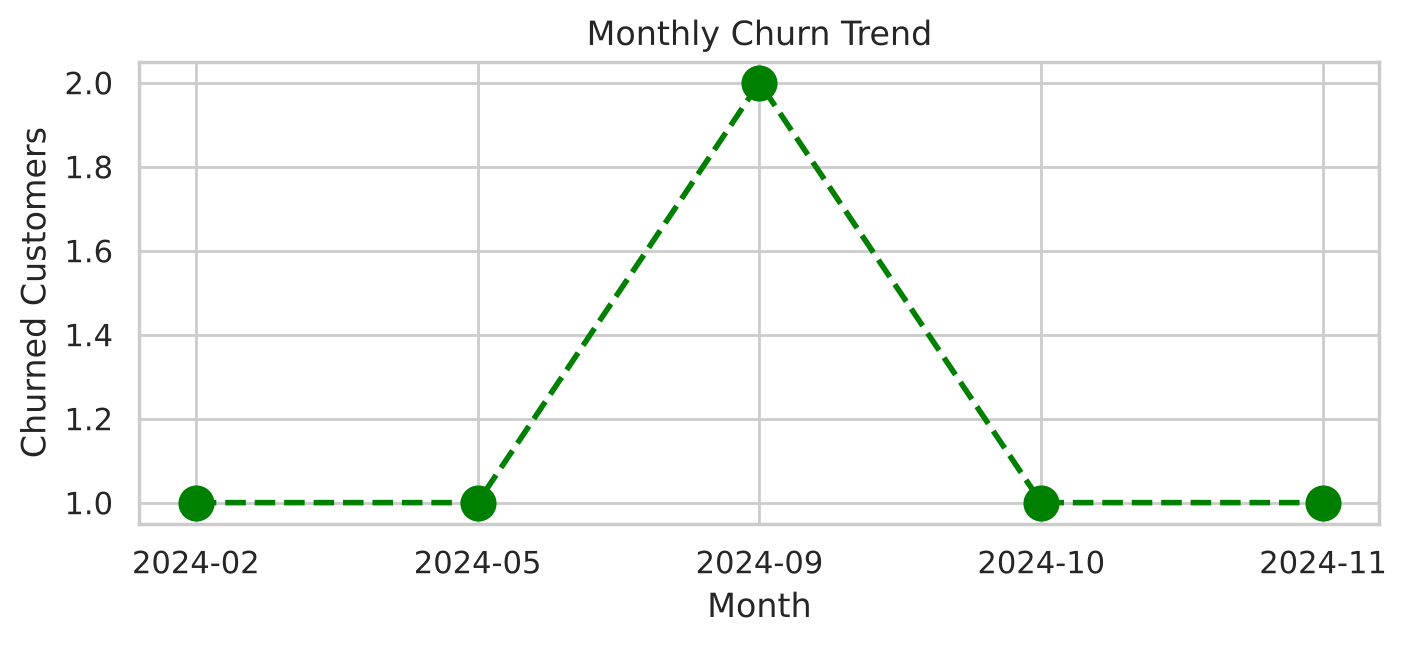

In [53]:
 #4.1 Monthly Churn Trend (Time Series KPI)

df_visual['cancellation_month'] = df_visual['cancellation_date'].dt.to_period('M')

churn_trend = df_visual[df_visual['churn_flag'] == 1].groupby('cancellation_month').size()

plt.figure(figsize=(8,3))
plt.plot(churn_trend.index.astype(str), churn_trend.values,  color='green', marker='o', linestyle='dashed',  linewidth=2, markersize=12)

plt.title('Monthly Churn Trend')
plt.xlabel('Month')
plt.ylabel('Churned Customers')
plt.show()

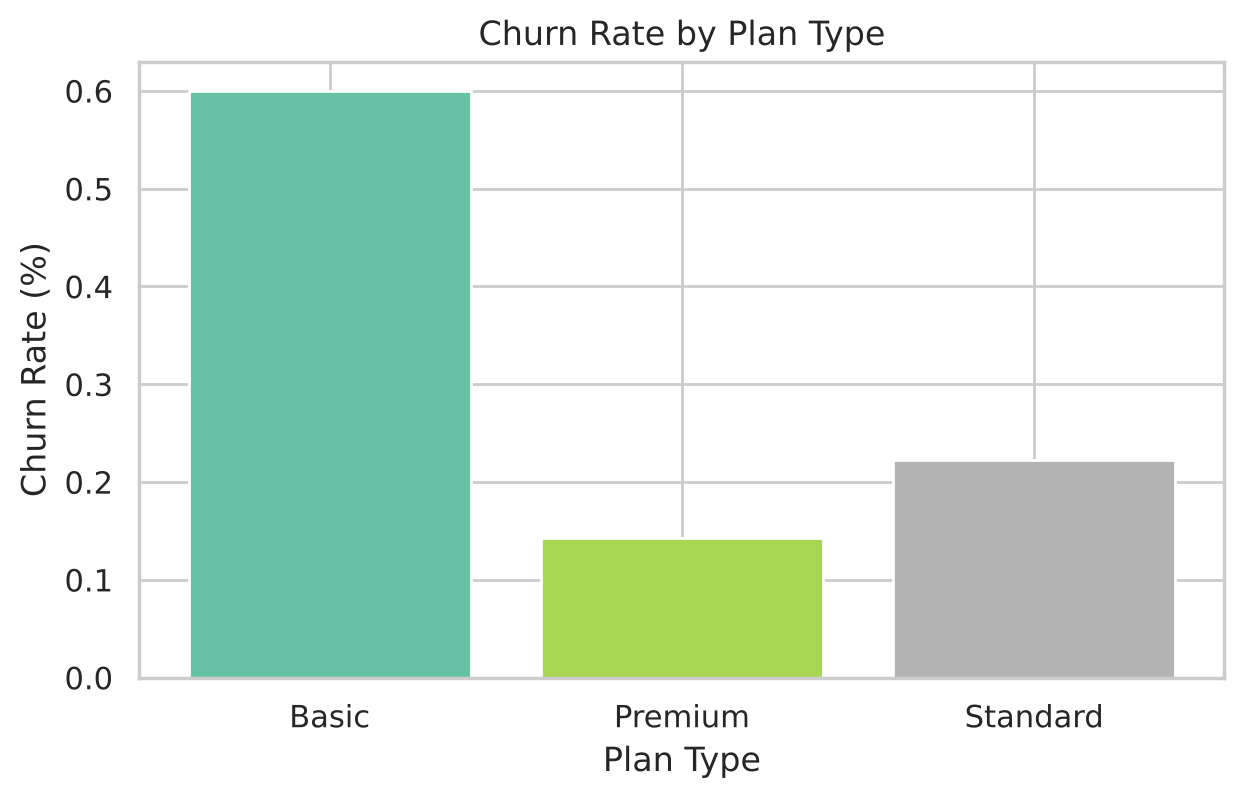

In [54]:
# 4.2 Churn Rate by Plan type
churn_plan = df_visual.groupby('plan_type')['churn_flag'].mean()

# colors = ['yellow', 'purple', 'blue']
colors = plt.cm.Set2(np.linspace(0, 1, len(churn_plan)))

plt.figure(figsize=(7,4))
plt.bar(churn_plan.index, churn_plan.values, color = colors)

plt.title('Churn Rate by Plan Type')
plt.xlabel('Plan Type')
plt.ylabel('Churn Rate (%)')
plt.show()

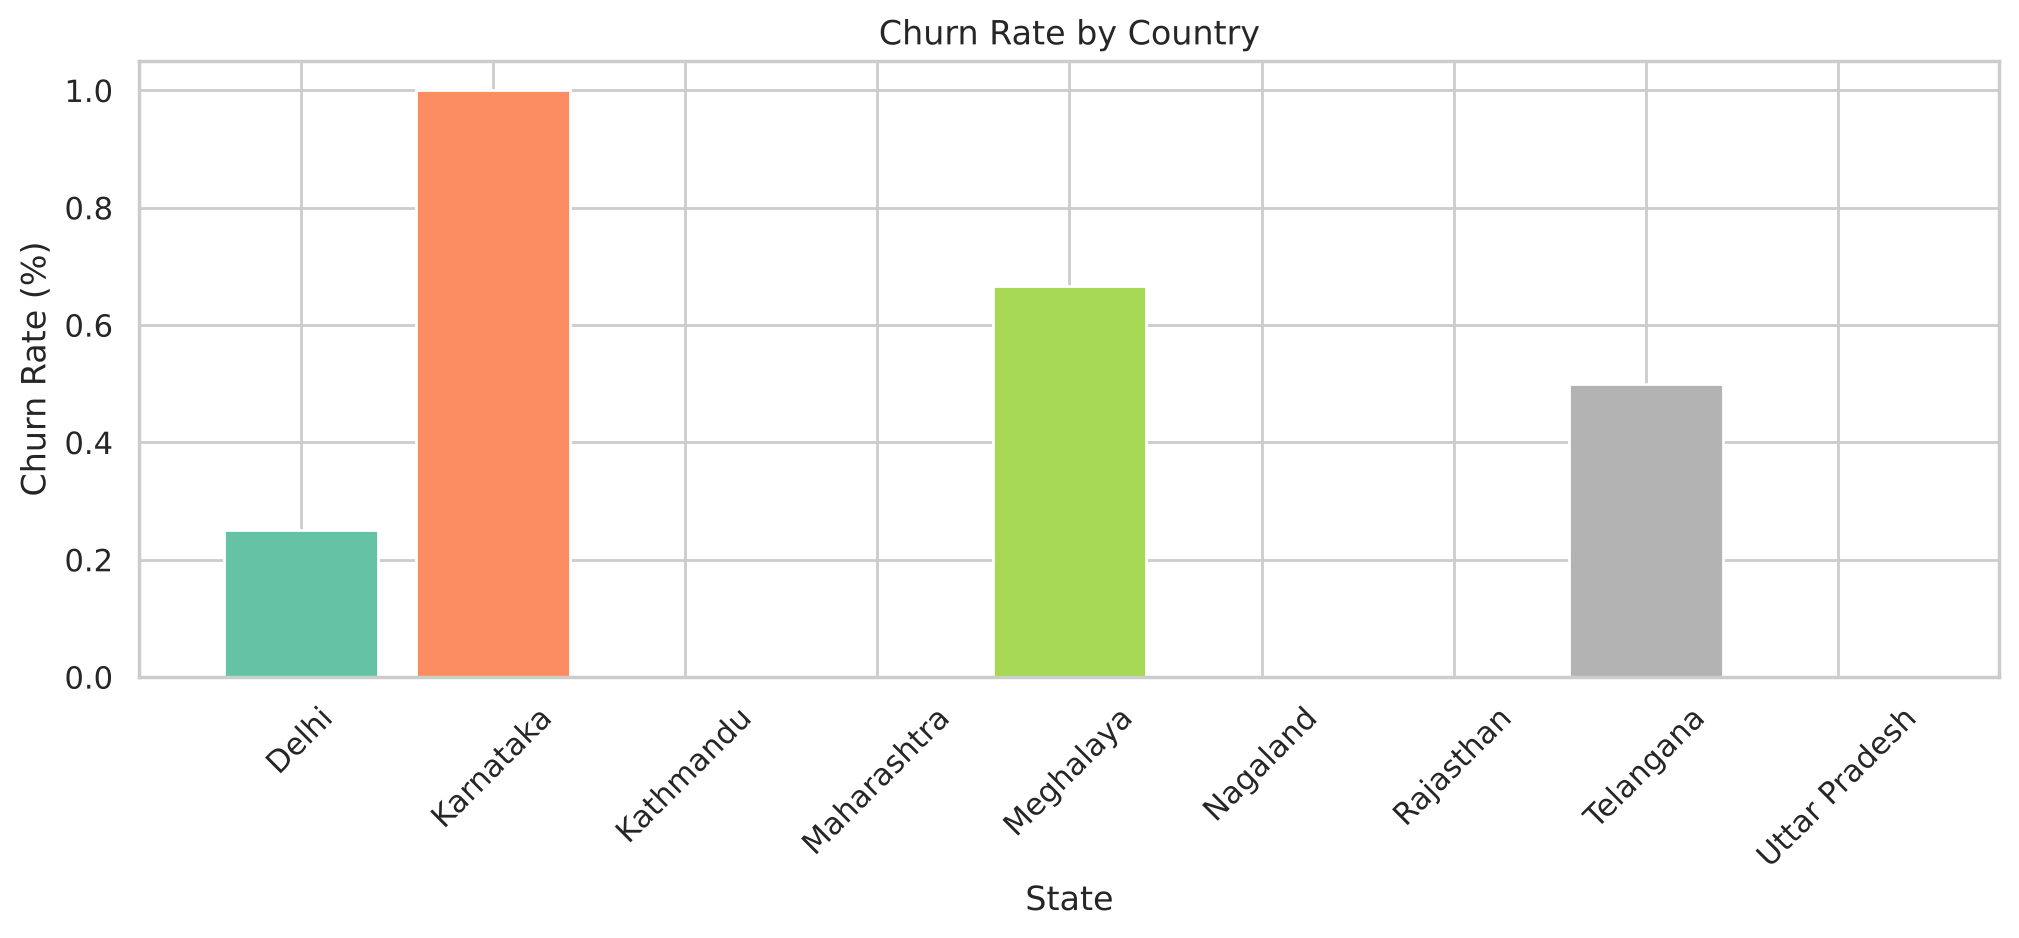

In [55]:
# 4.3 Churn by States
churn_plan = df_visual.groupby('state')['churn_flag'].mean()

# colors = ['yellow', 'purple', 'blue']
colors = plt.cm.Set2(np.linspace(0, 1, len(churn_plan)))

plt.figure(figsize=(12,4))
plt.bar(churn_plan.index, churn_plan.values, color = colors)

plt.title('Churn Rate by Country')
plt.xlabel('State')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=45)
plt.show()

In [56]:
# Visualization Using Seaborn

In [57]:
# Heatmap (Correlation Matrix)

In [58]:
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type', 'renewal_date', 'plan_type', 'contract_type', 'cancellation_date', 'cancellation_reason', 'monthly_charges', 'cltv',
       'churn_score', 'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob', 'complaint_date', 'escalations', 'csat_score', 'complaint_count', 'tenure_days', 'churn_risk',
       'cancellation_month'],
      dtype='str')

In [59]:
df_visual[['plan_type', 'contract_type', 'churn_score', 'churn_flag', 'churn_risk', 'escalations']].head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,Standard,Annual,12,0,low,0
1,Premium,Annual,91,1,high,1
2,Basic,Monthly,34,0,low,0
3,Premium,Annual,8,0,low,0
4,Standard,Monthly,88,1,high,1


In [60]:
# remove warnings
import warnings
warnings.filterwarnings("ignore")

In [61]:
# incorrect method of encoding - as numbers are not assigned based on priority
df_encoded = df_visual[['plan_type', 'contract_type', 'churn_score', 'churn_flag', 'churn_risk', 'escalations']]

categorial_cols = ['plan_type', 'contract_type', 'churn_risk']

for col in categorial_cols:
    df_encoded[col] = df_encoded[col].astype('category').cat.codes

<Axes: >

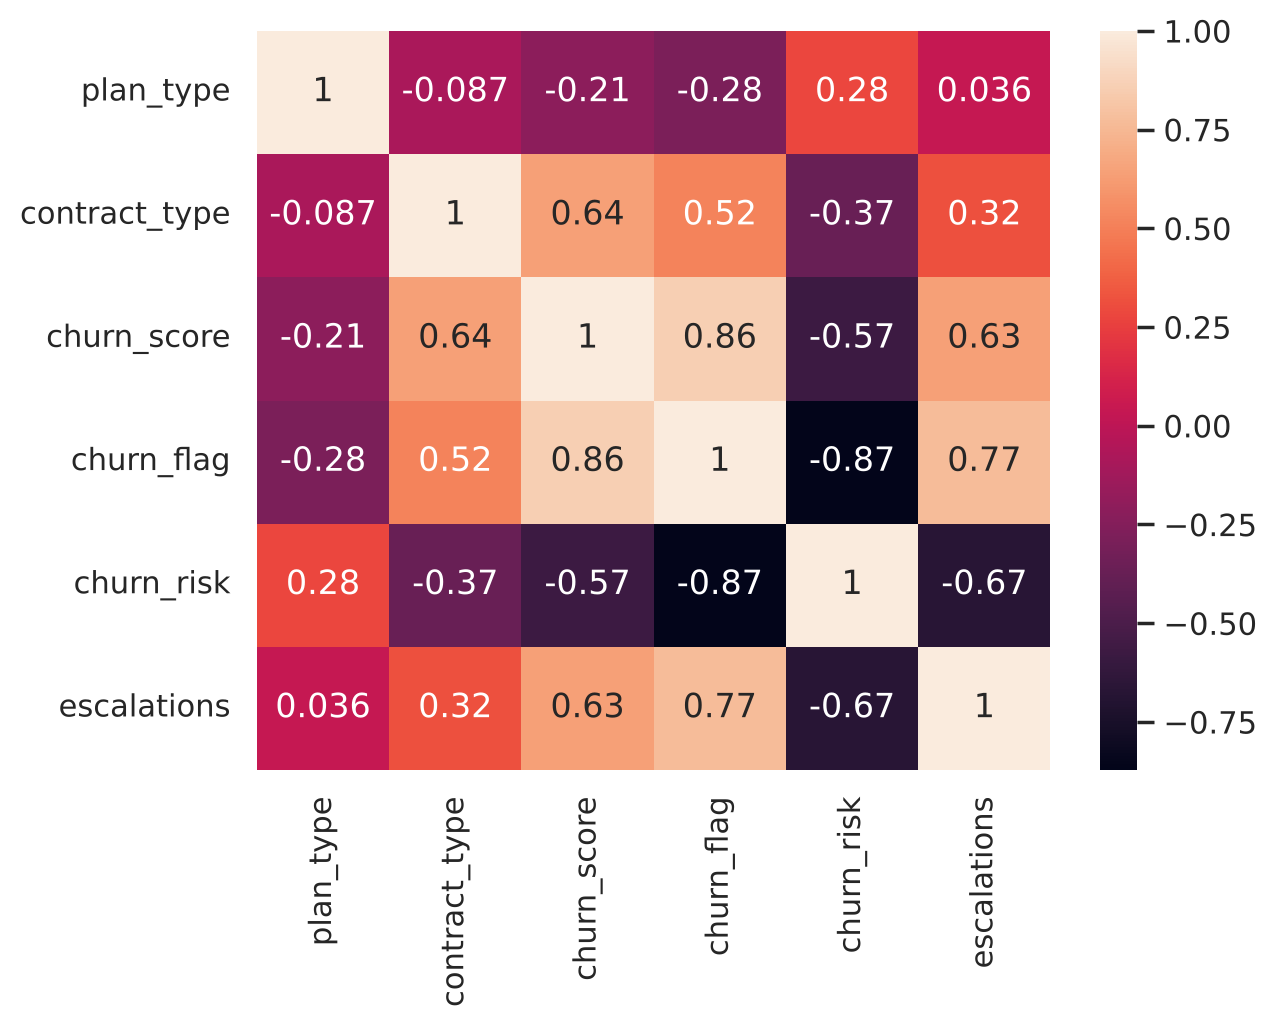

In [62]:
# Heatmap (correlation matrix)

sns.heatmap(df_encoded.corr(), annot=True)

In [63]:
print('plan_type :', df_visual['plan_type'].unique())
print('contract_type :', df_visual['contract_type'].unique())
print('churn_risk :', df_visual['churn_risk'].unique())

plan_type : <StringArray>
['Standard', 'Premium', 'Basic']
Length: 3, dtype: str
contract_type : <StringArray>
['Annual', 'Monthly']
Length: 2, dtype: str
churn_risk : <StringArray>
['low', 'high', 'med']
Length: 3, dtype: str


In [64]:
# Correct method of encoding - based on priority
df_encoded = df_visual[['plan_type', 'contract_type', 'churn_score', 'churn_flag', 'churn_risk', 'escalations']]

order_mappings = {
    'plan_type' : ['Basic', 'Standard', 'Premium'],
    'contract_type' : ['Monthly', 'Annual'],
    'churn_risk': ['low', 'med', 'high']
    }

for col, order in order_mappings.items():
    df_encoded[col] = pd.Categorical(df_encoded[col].astype('category'), categories=order, ordered=True).codes

In [65]:
df_visual[['plan_type', 'contract_type', 'churn_score', 'churn_flag', 'churn_risk', 'escalations']].head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,Standard,Annual,12,0,low,0
1,Premium,Annual,91,1,high,1
2,Basic,Monthly,34,0,low,0
3,Premium,Annual,8,0,low,0
4,Standard,Monthly,88,1,high,1


In [66]:
df_encoded.head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,1,1,12,0,0,0
1,2,1,91,1,2,1
2,0,0,34,0,0,0
3,2,1,8,0,0,0
4,1,0,88,1,2,1


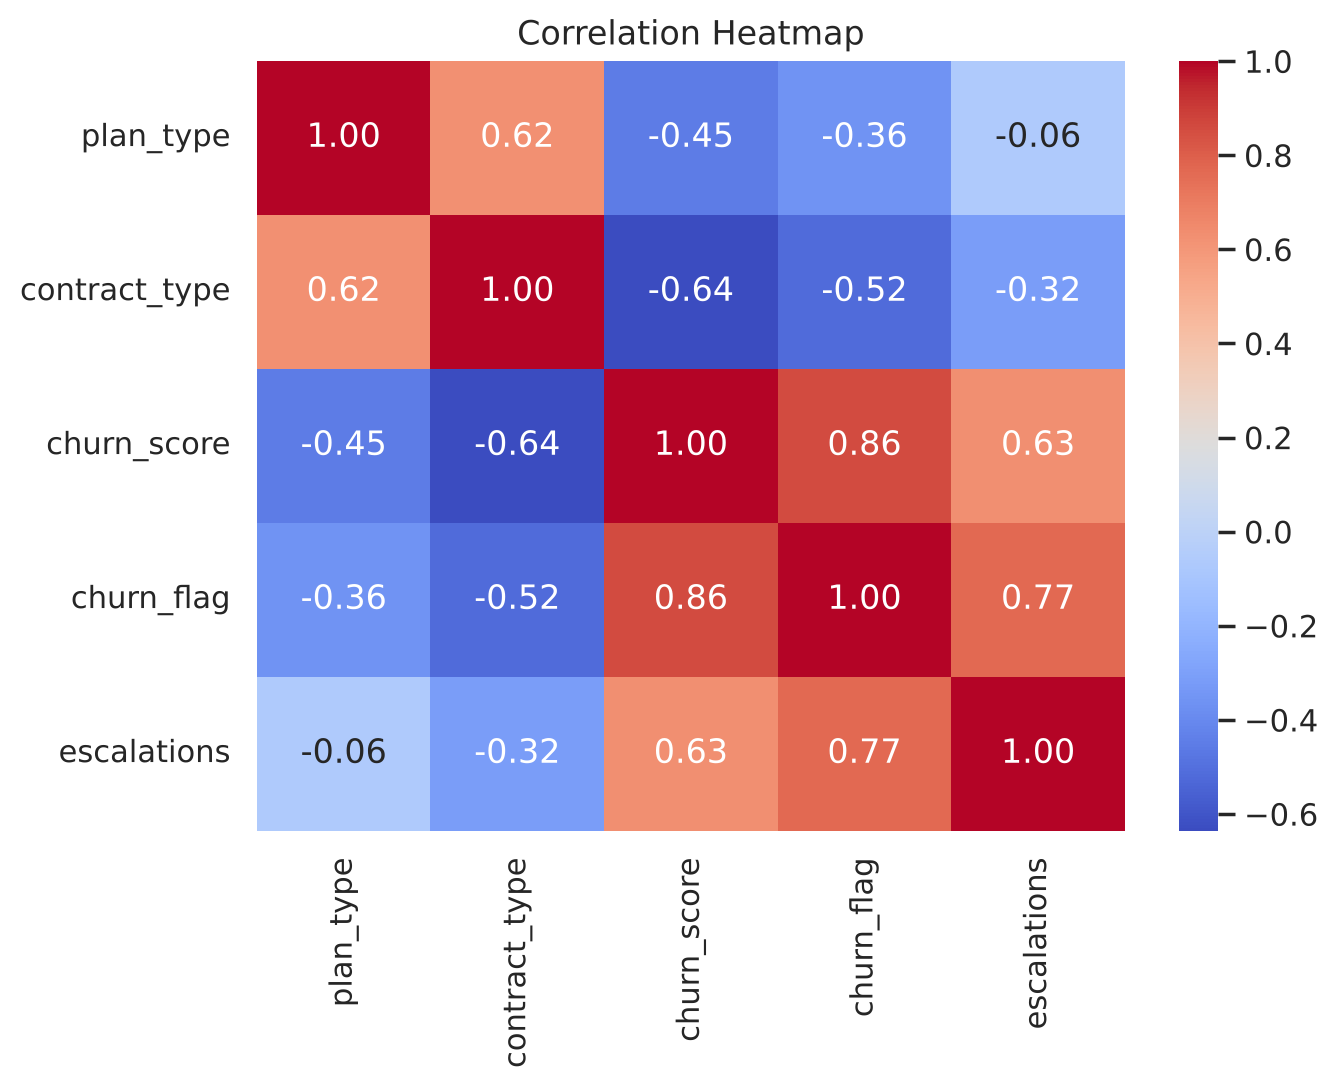

In [67]:
# Heatmap (correlation matrix)
# churn_risk is derived from churn_score, so it is dropped to avoid a circular correlation
plt.figure(figsize=(7,5))
sns.heatmap(df_encoded.drop(columns=['churn_risk']).corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

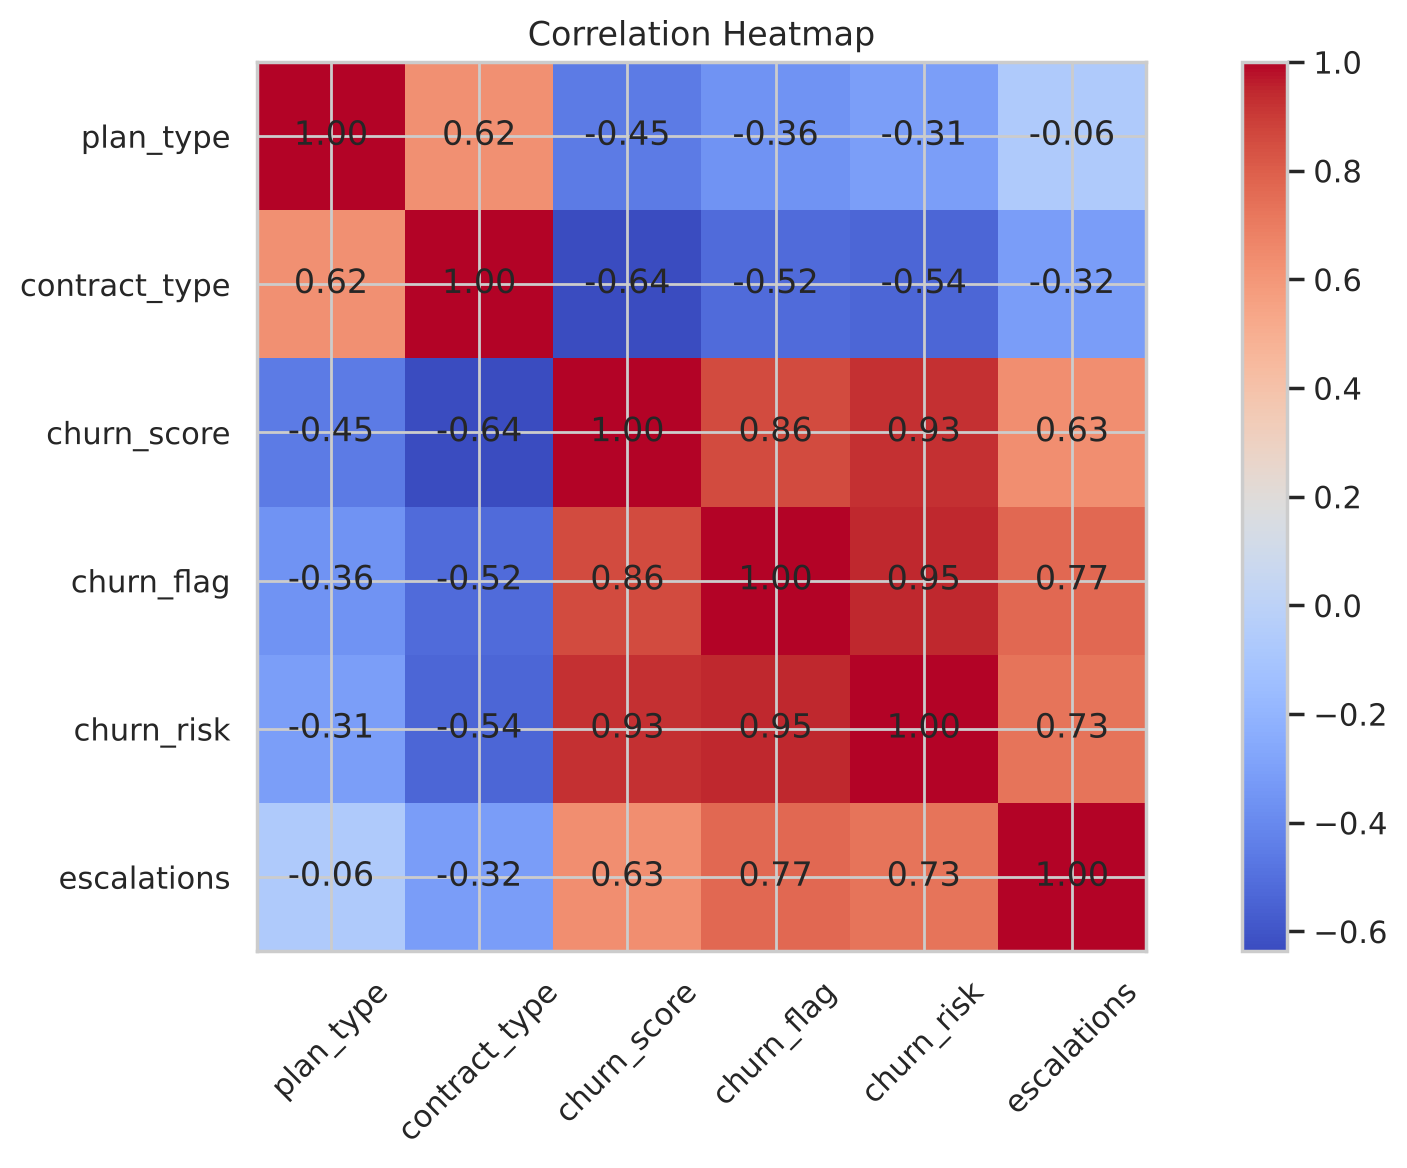

In [68]:
# Heatmap Using Matplotlib - difficult to plot it

corr_matrix = df_encoded.corr() # Correlation matrix

fig, ax = plt.subplots(figsize=(10, 6)) # Create figure

cax = ax.imshow(corr_matrix, cmap='coolwarm') # Heatmap

fig.colorbar(cax) # Add colorbar

# Axis labels
ax.set_xticks(np.arange(len(corr_matrix.columns)))
ax.set_yticks(np.arange(len(corr_matrix.columns)))

ax.set_xticklabels(corr_matrix.columns, rotation=45)
ax.set_yticklabels(corr_matrix.columns)

# Annotate values inside cells
for i in range(len(corr_matrix.columns)):
    for j in range(len(corr_matrix.columns)):
        ax.text(
            j,
            i,
            f"{corr_matrix.iloc[i, j]:.2f}",
            ha='center',
            va='center'
        )

plt.title('Correlation Heatmap') # Title

plt.tight_layout()
plt.show()

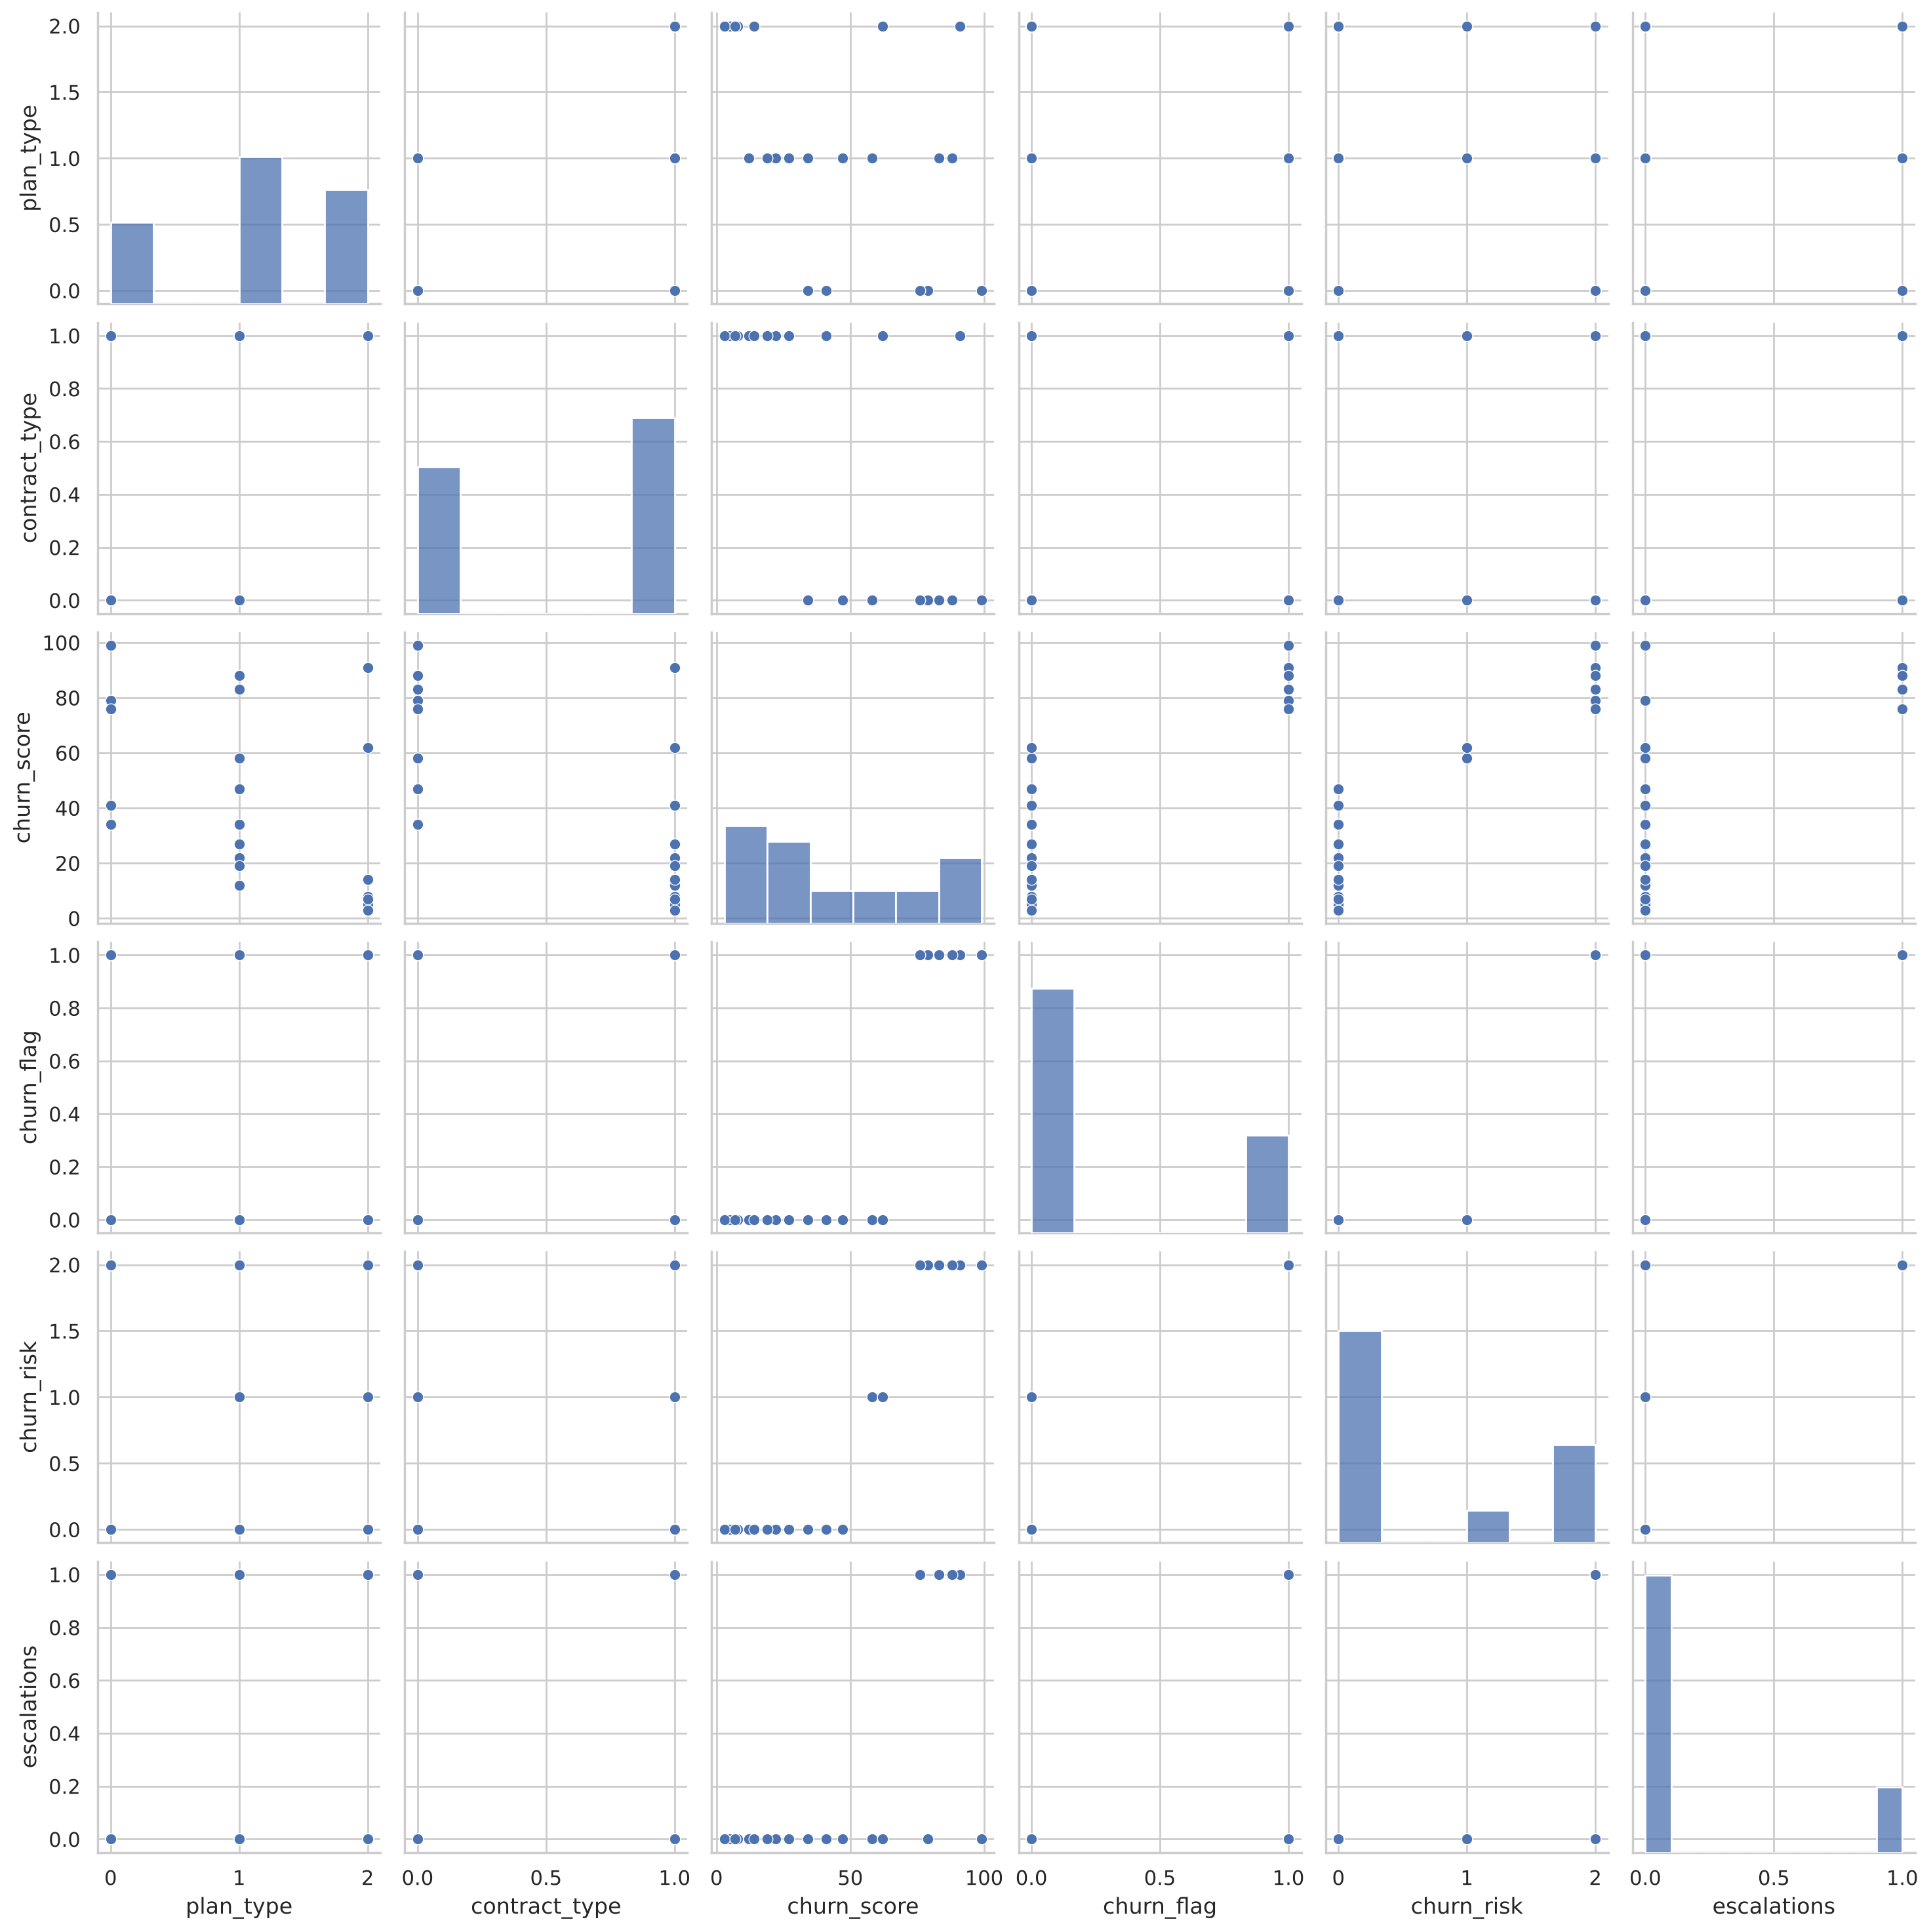

In [69]:
sns.pairplot(df_encoded)

In [70]:
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type', 'renewal_date', 'plan_type', 'contract_type', 'cancellation_date', 'cancellation_reason', 'monthly_charges', 'cltv',
       'churn_score', 'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob', 'complaint_date', 'escalations', 'csat_score', 'complaint_count', 'tenure_days', 'churn_risk',
       'cancellation_month'],
      dtype='str')

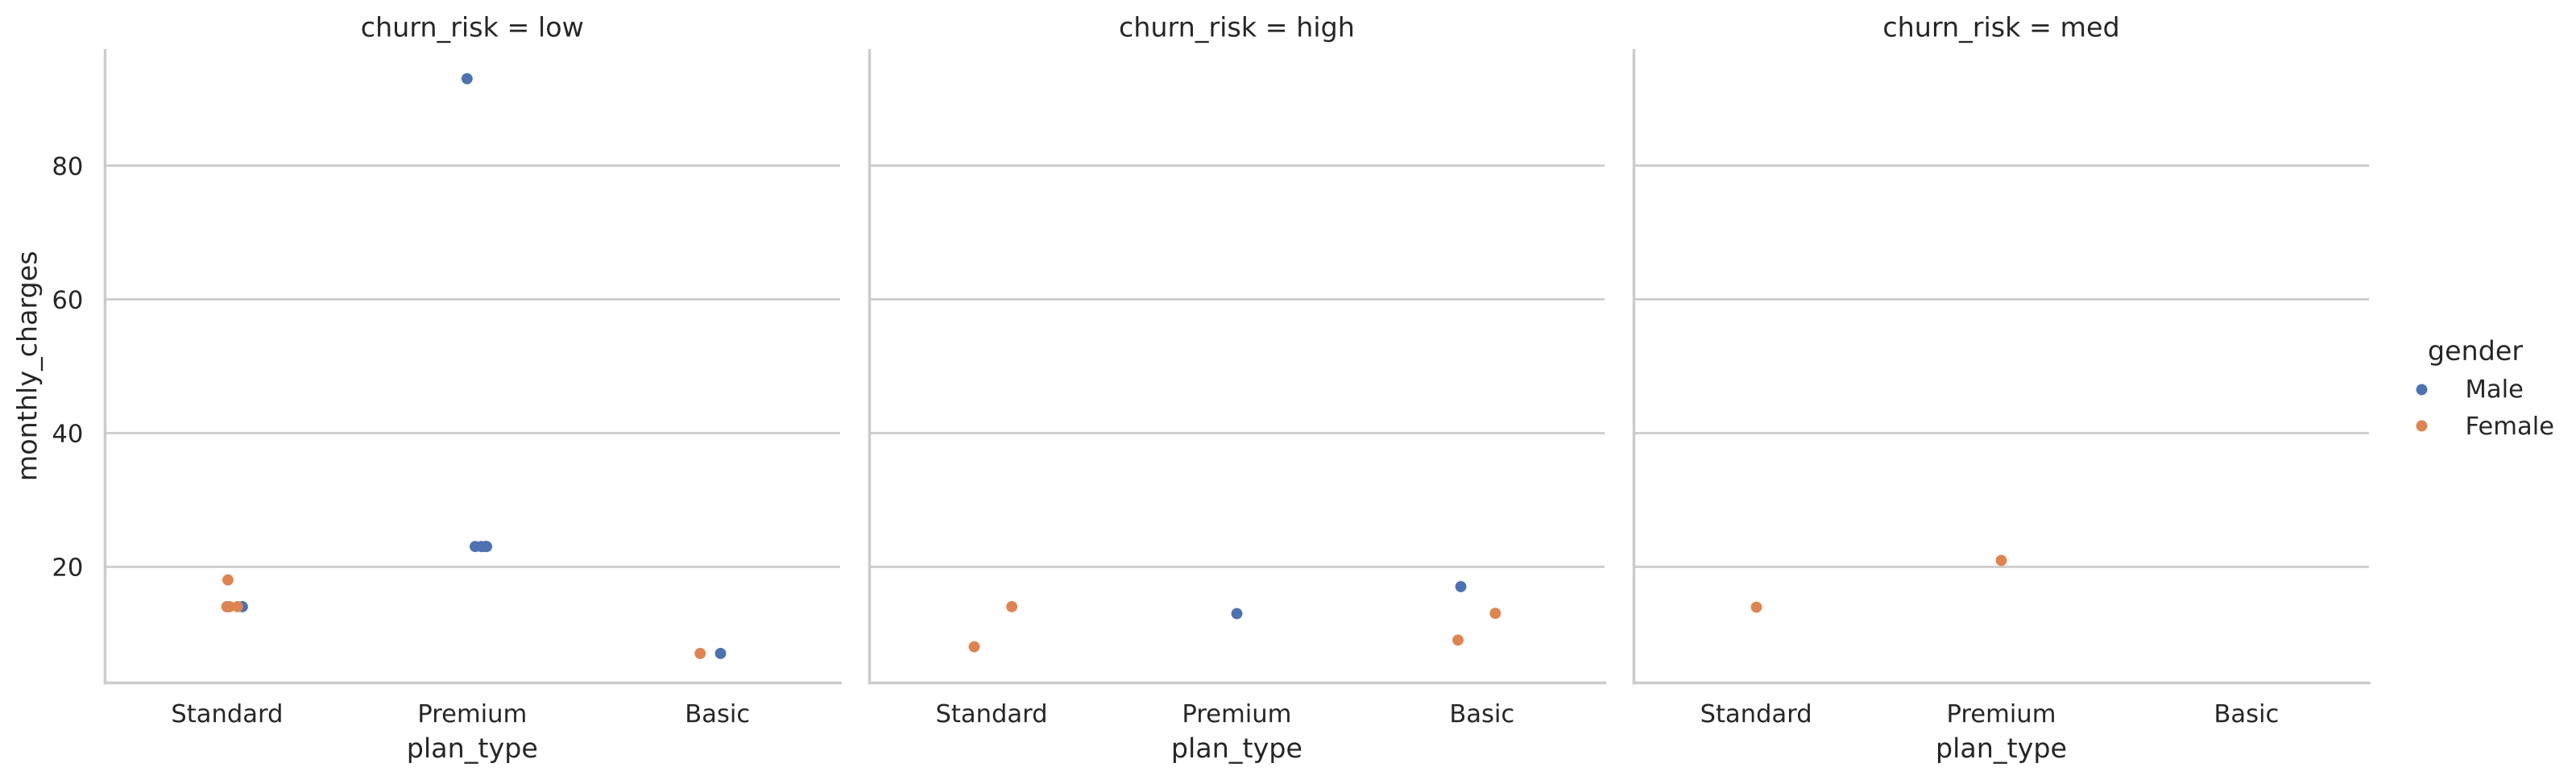

In [71]:
sns.catplot(data=df_visual,
    x='plan_type',
    y='monthly_charges',
    hue='gender',
    col='churn_risk')

In [72]:
# Pivot Table
pd.pivot_table(
    df_visual,
    index='plan_type',
    values='churn_flag',
    aggfunc = 'mean'
)

,churn_flag
plan_type,
Basic,0.600000
Premium,0.142857
Standard,0.222222


In [73]:
# pivot table using multiple cols and agg type
pd.pivot_table(
    df_visual,
    index='plan_type',
    values=['monthly_charges', 'customerid', 'churn_flag'],
    aggfunc = {
        'monthly_charges' : 'sum',
        'customerid' : 'nunique',
        'churn_flag' : 'mean'
    }
)

,churn_flag,customerid,monthly_charges
plan_type,,,
Basic,0.600000,5,52.95
Premium,0.142857,7,218.93
Standard,0.222222,9,123.91


## SQL Analysis (SQLite)
Cleaned tables are loaded back into SQLite and queried with basic SQL.

In [74]:
# reload CLEANED tables into SQLite
customer.to_sql("customers", conn, if_exists="replace", index=False)
subs.to_sql("subscriptions", conn, if_exists="replace", index=False)
support.to_sql("support", conn, if_exists="replace", index=False)

7

In [75]:
# Q1. Churn rate by plan
q1 = """
SELECT plan_type,
       COUNT(*) AS customers,
       SUM(churn_flag) AS churned,
       ROUND(100.0 * SUM(churn_flag) / COUNT(*), 2) AS churn_rate_pct
FROM subscriptions
GROUP BY plan_type
ORDER BY churn_rate_pct DESC
"""
pd.read_sql_query(q1, conn)

,plan_type,customers,churned,churn_rate_pct
0,Basic,5,3,60.00
1,Standard,9,2,22.22
2,Premium,7,1,14.29


In [76]:
# Q2. Cancellation reasons
q2 = """
SELECT cancellation_reason, COUNT(*) AS customers
FROM subscriptions
WHERE cancellation_reason IS NOT NULL
GROUP BY cancellation_reason
ORDER BY customers DESC
"""
pd.read_sql_query(q2, conn)

,cancellation_reason,customers
0,Switched to competitor,2
1,Too expensive,1
2,Poor streaming quality,1
3,Not enough content,1
4,Forgot to cancel trial,1


In [77]:
# Q3. Churn rate by state
q3 = """
SELECT c.state,
       COUNT(*) AS customers,
       SUM(s.churn_flag) AS churned
FROM subscriptions s
JOIN customers c ON c.customerid = s.customerid
GROUP BY c.state
ORDER BY churned DESC, customers DESC
"""
pd.read_sql_query(q3, conn)

,state,customers,churned
0,Meghalaya,3,2
1,Karnataka,2,2
2,Delhi,4,1
3,Telangana,2,1
4,Maharashtra,3,0
5,Kathmandu,2,0
6,Rajasthan,2,0
7,Uttar Pradesh,2,0
8,Nagaland,1,0


In [78]:
# Q4. Active customers with churn score >= 50 (watch list)
q4 = """
SELECT c.customer_name, c.state, s.plan_type, s.monthly_charges, s.churn_score
FROM subscriptions s
JOIN customers c ON c.customerid = s.customerid
WHERE s.churn_flag = 0 AND s.churn_score >= 50
ORDER BY s.churn_score DESC
"""
pd.read_sql_query(q4, conn)

,customer_name,state,plan_type,monthly_charges,churn_score
0,rikim,Meghalaya,Premium,20.99,62
1,parvati,Delhi,Standard,13.99,58


In [79]:
# Q5. Average monthly charges and CLTV by plan
q5 = """
SELECT plan_type,
       ROUND(AVG(monthly_charges), 2) AS avg_monthly_charges,
       ROUND(AVG(cltv), 0) AS avg_cltv
FROM subscriptions
GROUP BY plan_type
"""
pd.read_sql_query(q5, conn)

,plan_type,avg_monthly_charges,avg_cltv
0,Basic,10.59,195.0
1,Premium,31.28,1574.0
2,Standard,13.77,589.0


## Key Insights
1. **Churn rate is 28.57%** (6 of 21 customers); retention is 71.43%.
2. **Basic plan churns the most:** 60% (3 of 5) vs Standard 22% (2 of 9) and Premium 14% (1 of 7).
3. **Escalated complaints go with churn:** all 4 customers whose latest complaint was escalated churned (correlation 0.77).
4. **Cancellation reasons:** "Switched to competitor" is the most common (2 of 6); price, content, streaming quality and a forgotten trial account for one each.
5. **Revenue:** 73.94 monthly revenue already lost; 34.98 more is at risk from 2 active customers with churn score >= 50.
6. **Data note:** one Premium customer is charged 92.99 vs ~23 for the others (likely an entry error), which pulls ARPU (18.85) and Premium average charges up.

## Recommendations
- Offer upgrade or discount paths to Basic-plan users before renewal.
- Trigger retention outreach as soon as a complaint is escalated or CSAT is low.
- Contact the 2 active watch-list customers first (SQL Q4).

## Limitations
Only 21 customers, so results are directional, not statistically significant.